In [214]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [215]:
df = pd.read_csv(r"C:\Users\Inchara\Downloads\used_cars_eda_dataset.csv")


In [216]:
df.head(10)

,Car_Name,Year,Selling_Price_INR,Kms_Driven,Fuel_Type,Transmission,Owner
0,Maruti Swift,2018,520000,42000,Petrol,Manual,First Owner
1,Hyundai i20,2019,650000,35000,Petrol,Manual,First Owner
2,Honda City,2017,720000,56000,Petrol,Automatic,Second Owner
3,Tata Tiago,2020,480000,22000,Petrol,Manual,First Owner
4,Maruti Baleno,2019,610000,30000,Petrol,Manual,First Owner
5,Hyundai Creta,2018,950000,48000,Diesel,Manual,First Owner
6,Tata Nexon,2021,820000,18000,Petrol,Manual,First Owner
7,Mahindra XUV500,2016,850000,78000,Diesel,Manual,Second Owner
8,Toyota Innova,2017,1150000,65000,Diesel,Manual,First Owner
9,Maruti Alto,2015,260000,72000,Petrol,Manual,Second Owner


In [217]:
df.info() #summary of data

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Car_Name           50 non-null     str  
 1   Year               50 non-null     int64
 2   Selling_Price_INR  50 non-null     int64
 3   Kms_Driven         50 non-null     int64
 4   Fuel_Type          50 non-null     str  
 5   Transmission       50 non-null     str  
 6   Owner              50 non-null     str  
dtypes: int64(3), str(4)
memory usage: 4.6 KB


In [218]:
#statistical summary
df.describe()

,Year,Selling_Price_INR,Kms_Driven
count,50.000000,5.000000e+01,50.000000
mean,2018.600000,7.596000e+05,43000.000000
std,2.185294,3.835067e+05,22824.977368
min,2014.000000,2.600000e+05,11000.000000
25%,2017.000000,4.875000e+05,23250.000000
50%,2019.000000,6.600000e+05,40000.000000
75%,2020.000000,9.275000e+05,60250.000000
max,2022.000000,2.100000e+06,88000.000000


In [219]:
#missing values
df.isnull().sum()

Car_Name             0
Year                 0
Selling_Price_INR    0
Kms_Driven           0
Fuel_Type            0
Transmission         0
Owner                0
dtype: int64

In [220]:
#duplicate values
df.duplicated().sum()

np.int64(0)

In [221]:
#removal of duplicate value
df.drop_duplicates(inplace=True)

In [222]:
df.duplicated().sum()

np.int64(0)

In [223]:
#missing value treatments
df["Car_Name"]=df["Car_Name"].fillna(df["Car_Name"].mode()[0])
df["Fuel_Type"]=df["Fuel_Type"].fillna(df["Fuel_Type"].mode()[0])
df["Transmission"]=df["Transmission"].fillna(df["Transmission"].mode()[0])
df["Owner"]=df["Owner"].fillna(df["Owner"].mode()[0])

In [224]:
# recheck missing values
df.isnull().sum()

Car_Name             0
Year                 0
Selling_Price_INR    0
Kms_Driven           0
Fuel_Type            0
Transmission         0
Owner                0
dtype: int64

In [225]:
categorical_columns = df.select_dtypes(include = "str").columns

print(categorical_columns)

Index(['Car_Name', 'Fuel_Type', 'Transmission', 'Owner'], dtype='str')


In [226]:
for column in categorical_columns:
  print(
      column,
      ":",
      df[column].nunique(dropna = False),
      df[column].unique(),
      sep = "\n"
  )

Car_Name
:
50
<ArrowStringArray>
[     'Maruti Swift',       'Hyundai i20',        'Honda City',
        'Tata Tiago',     'Maruti Baleno',     'Hyundai Creta',
        'Tata Nexon',   'Mahindra XUV500',     'Toyota Innova',
       'Maruti Alto',      'Renault Kwid',       'Honda Amaze',
        'Kia Seltos',     'Toyota Glanza',     'Ford EcoSport',
    'Maruti Wagon R',     'Hyundai Verna',        'Tata Punch',
     'Mahindra Thar',       'Skoda Rapid',   'Volkswagen Polo',
      'Maruti Dzire',        'Honda Jazz',     'Hyundai Venue',
      'Tata Harrier',    'Maruti Celerio',    'Nissan Magnite',
   'Toyota Fortuner',    'Hyundai Santro',        'Honda WR-V',
     'Maruti Ertiga',         'Kia Sonet',       'Tata Altroz',
 'Hyundai Grand i10',   'Mahindra Bolero',      'Maruti Ignis',
       'Honda Civic',      'Toyota Yaris',    'Renault Duster',
         'MG Hector',   'Maruti S-Presso',   'Hyundai Alcazar',
       'Tata Safari',        'Honda Brio',        'Maruti XL6',
      '

In [227]:
#cleaning categorical variables
df_clean=df.copy()

In [228]:
text_columns=df_clean.select_dtypes(include="str").columns
for column in text_columns:
  df_clean[column]=df_clean[column].str.strip().str.lower()

In [229]:
df_clean.head()

,Car_Name,Year,Selling_Price_INR,Kms_Driven,Fuel_Type,Transmission,Owner
0,maruti swift,2018,520000,42000,petrol,manual,first owner
1,hyundai i20,2019,650000,35000,petrol,manual,first owner
2,honda city,2017,720000,56000,petrol,automatic,second owner
3,tata tiago,2020,480000,22000,petrol,manual,first owner
4,maruti baleno,2019,610000,30000,petrol,manual,first owner


In [230]:
#Univariate Analysis

df["Year"].value_counts()

Year
2018    7
2019    7
2017    7
2020    7
2021    7
2016    6
2022    5
2015    3
2014    1
Name: count, dtype: int64

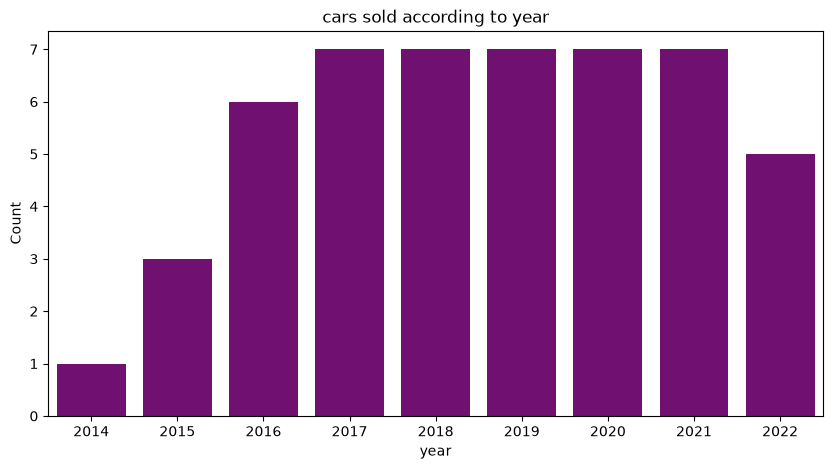

In [231]:
plt.figure(figsize = (10,5))
sns.countplot(data = df, x = "Year",color = "purple")
plt.title("cars sold according to year")
plt.xlabel("year")
plt.ylabel("Count")
plt.show()

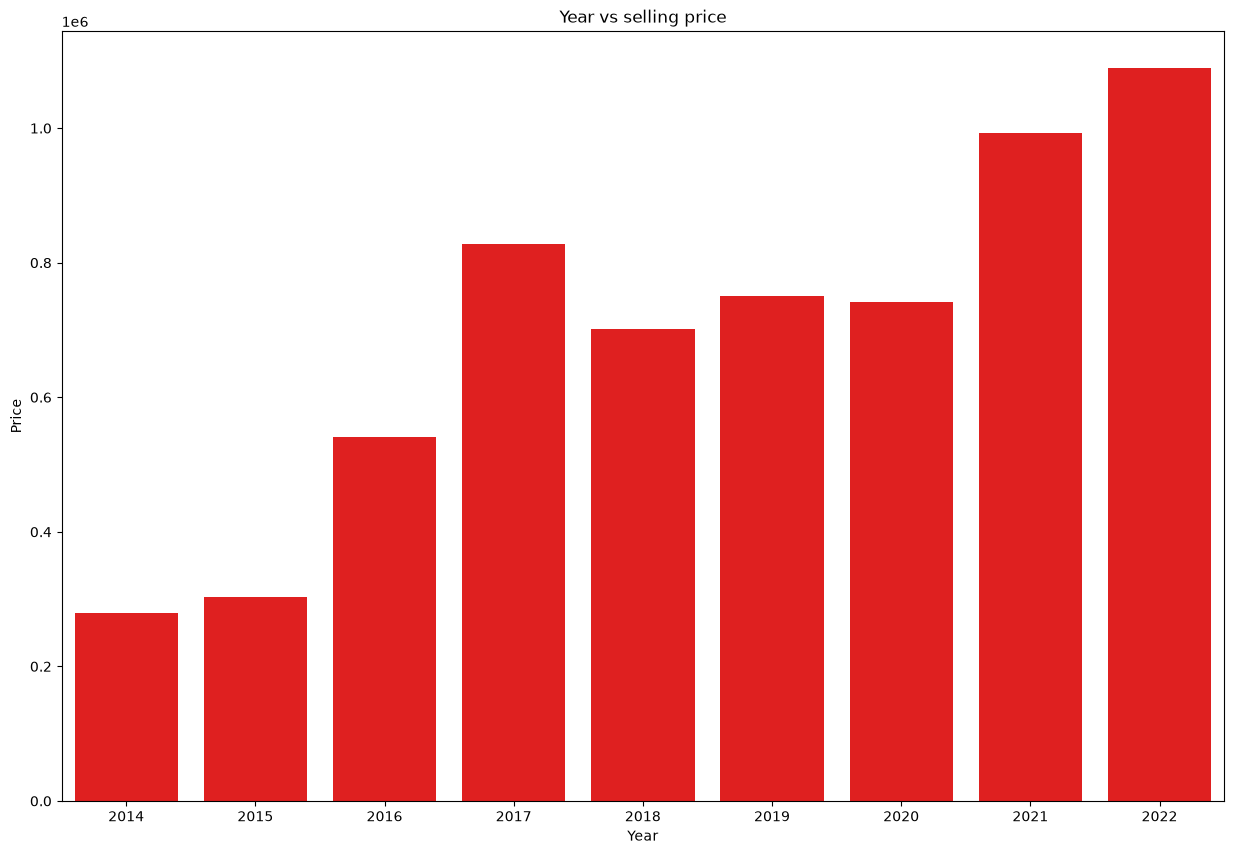

In [232]:
#Bivariate Analysis
plt.figure(figsize = (15,10))
sns.barplot(data = df, x = "Year",y = "Selling_Price_INR",color = "red",errorbar = None)
plt.title("Year vs selling price")
plt.xlabel("Year")
plt.ylabel("Price")
plt.show()

In [233]:
#Observation: The bar graph helps examine the relationship between the manufacturing year and car price.Newer cars may have higher prices, but this should be confirmed from the plotted data.Use the actual graph to write your observations rather than guessing the results.

In [234]:
#insight2
#Comparing manufacturing year with selling price helps determine whether prices tend to differ between newer and older cars. The direction of this relationship should be confirmed from the graph or average prices by year.

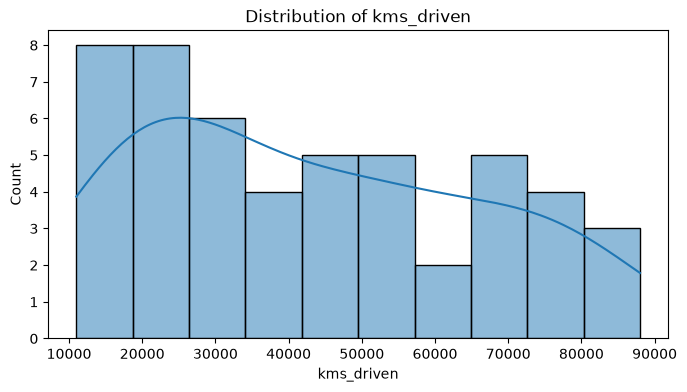

In [235]:
plt.figure(figsize=(8,4))
sns.histplot(data=df_clean, x="Kms_Driven" ,bins=10, kde=True)
plt.title("Distribution of kms_driven")
plt.xlabel("kms_driven")
plt.ylabel("Count")
plt.show()

In [236]:
numeric_df_clean=df_clean.select_dtypes(include="number")

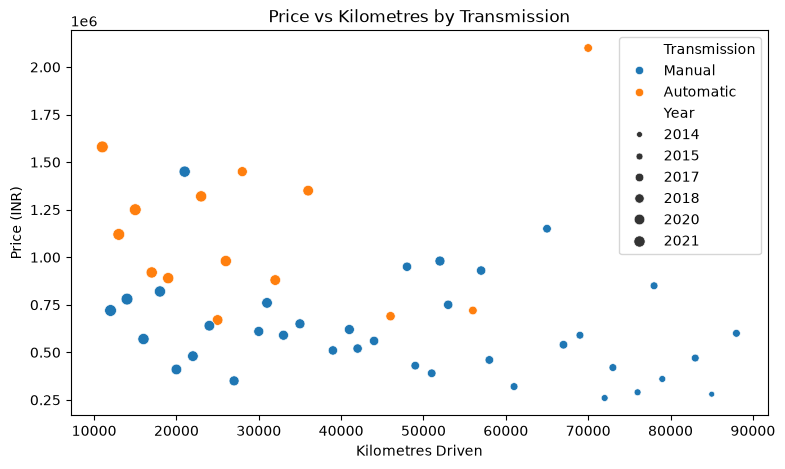

In [237]:
# Multivariate Analysis 2

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Kms_Driven",
    y="Selling_Price_INR",
    hue="Transmission",
    size="Year"
)

plt.title("Price vs Kilometres by Transmission")
plt.xlabel("Kilometres Driven")
plt.ylabel("Price (INR)")
plt.show()

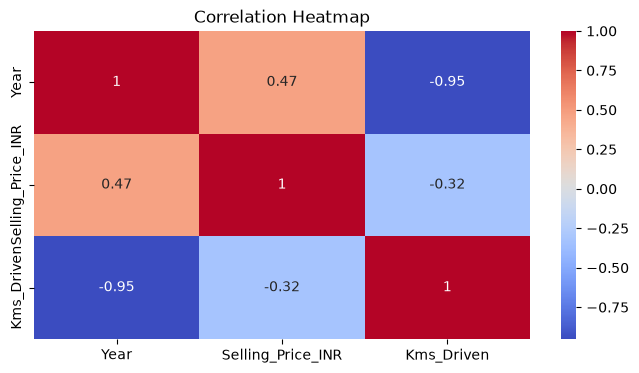

In [238]:
#Multi variate analysis
plt.figure(figsize=(8,4))
sns.heatmap(numeric_df_clean.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

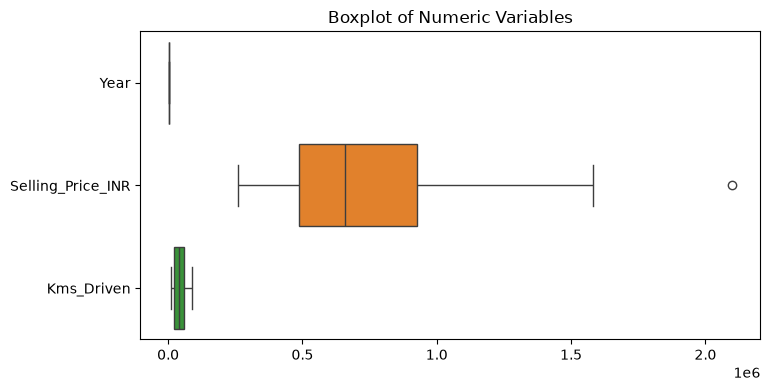

In [239]:
# Outlier
plt.figure(figsize = (8,4))
sns.boxplot(data = numeric_df_clean, orient = "h")
plt.title("Boxplot of Numeric Variables")
plt.show()

In [240]:
import numpy as np

#Outlier Removal
for i in numeric_df_clean.columns:
  Q1 = df_clean[i].quantile(0.25)
  Q3 = df_clean[i].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  df_clean = df_clean[(df_clean[i] >= lower_bound) & (df_clean[i] <= upper_bound)]

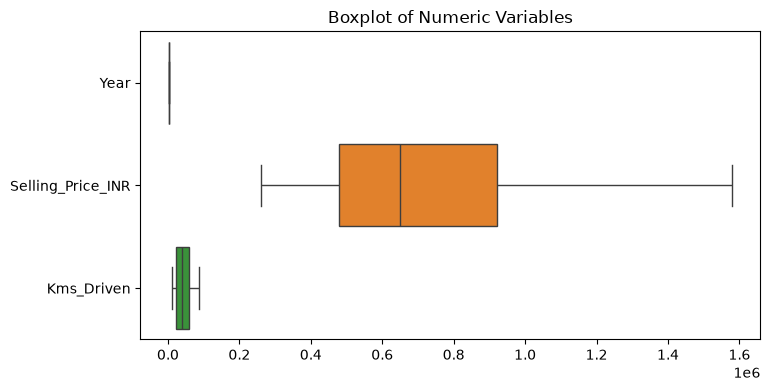

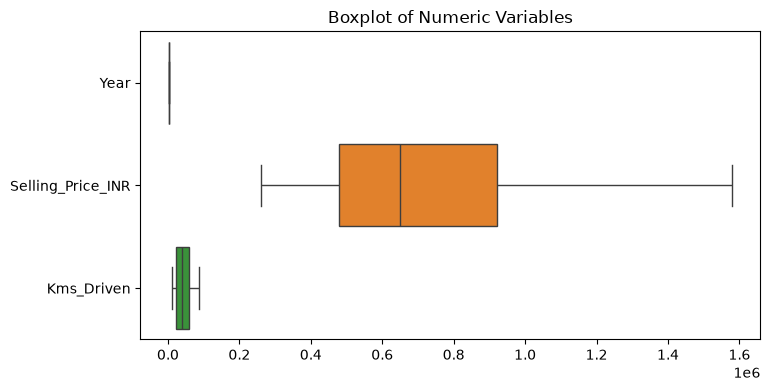

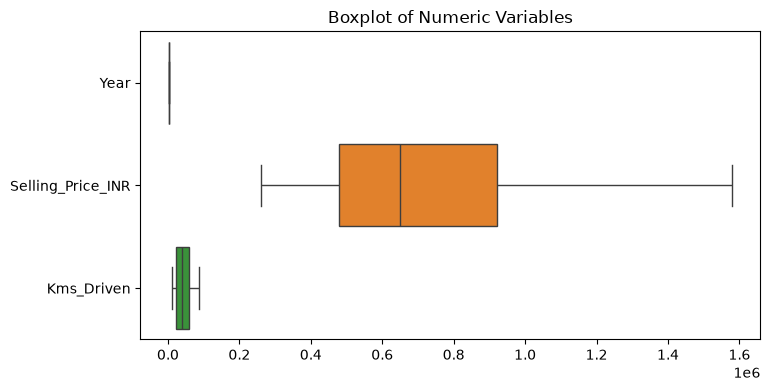

In [241]:
# rechecking on outlier

# Reset the index

df_clean = df_clean.reset_index(drop=True)

# select updated numerical columns

numeric_df_clean = df_clean.select_dtypes(include = np.number)

for i in numeric_df_clean.columns:

  plt.figure(figsize = (8,4))

  sns.boxplot(data = numeric_df_clean, orient = "h")

  plt.title("Boxplot of Numeric Variables")

  plt.show()

In [242]:
categorical_columns = df_clean.select_dtypes(include = "str").columns

print(categorical_columns)

Index(['Car_Name', 'Fuel_Type', 'Transmission', 'Owner'], dtype='str')


In [243]:
# one -hot encoding

df_encoded = pd.get_dummies(df_clean, columns = categorical_columns, drop_first = True,dtype = int)

In [244]:
print(df_encoded.dtypes)

df_encoded.head()

Year                          int64
Selling_Price_INR             int64
Kms_Driven                    int64
Car_Name_honda amaze          int64
Car_Name_honda brio           int64
Car_Name_honda city           int64
Car_Name_honda civic          int64
Car_Name_honda jazz           int64
Car_Name_honda wr-v           int64
Car_Name_hyundai alcazar      int64
Car_Name_hyundai creta        int64
Car_Name_hyundai grand i10    int64
Car_Name_hyundai i20          int64
Car_Name_hyundai santro       int64
Car_Name_hyundai venue        int64
Car_Name_hyundai verna        int64
Car_Name_kia seltos           int64
Car_Name_kia sonet            int64
Car_Name_mahindra bolero      int64
Car_Name_mahindra scorpio     int64
Car_Name_mahindra thar        int64
Car_Name_mahindra xuv500      int64
Car_Name_maruti alto          int64
Car_Name_maruti baleno        int64
Car_Name_maruti celerio       int64
Car_Name_maruti dzire         int64
Car_Name_maruti ertiga        int64
Car_Name_maruti ignis       

,Year,Selling_Price_INR,Kms_Driven,Car_Name_honda amaze,Car_Name_honda brio,Car_Name_honda city,Car_Name_honda civic,Car_Name_honda jazz,Car_Name_honda wr-v,Car_Name_hyundai alcazar,...,Car_Name_toyota etios,Car_Name_toyota glanza,Car_Name_toyota innova,Car_Name_toyota yaris,Car_Name_volkswagen polo,Car_Name_volkswagen vento,Fuel_Type_petrol,Transmission_manual,Owner_second owner,Owner_third owner
0,2018,520000,42000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
1,2019,650000,35000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
2,2017,720000,56000,0,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,1,0
3,2020,480000,22000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
4,2019,610000,30000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0


In [245]:
df.to_csv("used_cars_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
